In [3]:
# problem : Rossmann is challenging you to predict 6 weeks of daily sales for 1,115 stores located across Germany. 

In [4]:
import numpy as num
import pandas as pd

In [5]:
import opendatasets as od
od.download('https://www.kaggle.com/c/rossmann-store-sales')

Skipping, found downloaded files in ".\rossmann-store-sales" (use force=True to force download)


In [6]:
import os
os.listdir('rossmann-store-sales')

['sample_submission.csv', 'store.csv', 'test.csv', 'train.csv']

In [7]:
ross_df = pd.read_csv('./rossmann-store-sales/train.csv', low_memory=False)
#low_memory means telling a data tool to load an entire file into your computer's memory (RAM)

In [8]:
ross_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [9]:
store_df = pd.read_csv('./rossmann-store-sales/store.csv')

In [10]:
store_df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [11]:
merged_df = ross_df.merge(store_df, how= 'left', on = 'Store')
#All rows from ross_df are kept, and store_df's columns get pulled in and matched based on 'Store'. 
#how='left' means: keep every row from ross_df (left), and attach matching columns from store_df (right) wherever the Store values match.
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [12]:
test_df = pd.read_csv('rossmann-store-sales/test.csv')
test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0
...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0
41084,41085,1112,6,2015-08-01,1.0,0,0,0
41085,41086,1113,6,2015-08-01,1.0,0,0,0
41086,41087,1114,6,2015-08-01,1.0,0,0,0


In [13]:
merged_test_df = test_df.merge(store_df, how='left',on='Store')
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [14]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  str    
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  str    
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  str    
 10  Assortment                 1017209 non-null  str    
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionOpenSinceYea

In [15]:
round(merged_df.describe().T,2)
#This transposes the result — flips rows and columns. Instead of statistics as rows and your data columns going across,
#"Give me summary statistics for every numeric column, flip it so columns become rows, and b

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.43,321.91,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,4.00,2.00,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.82,3849.93,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.15,464.41,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.83,0.38,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.38,0.49,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.18,0.38,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,1014567.0,5430.09,7715.32,20.0,710.0,2330.0,6890.0,75860.0
CompetitionOpenSinceMonth,693861.0,7.22,3.21,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,693861.0,2008.69,5.99,1900.0,2006.0,2010.0,2013.0,2015.0


In [16]:

merged_df.duplicated().sum()
#every row in the DataFrame and returns a Boolean Series (True/False), keep the true and false value,then if True Sum

np.int64(0)

In [17]:
merged_df['Date'] = pd.to_datetime(merged_df.Date)
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [18]:
merged_test_df['Date'] = pd.to_datetime(merged_test_df.Date)

In [19]:
merged_df.Date.min(), merged_df.Date.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [20]:
merged_test_df.Date.min(), merged_test_df.Date.max()

(Timestamp('2015-08-01 00:00:00'), Timestamp('2015-09-17 00:00:00'))

<Axes: xlabel='Sales', ylabel='Count'>

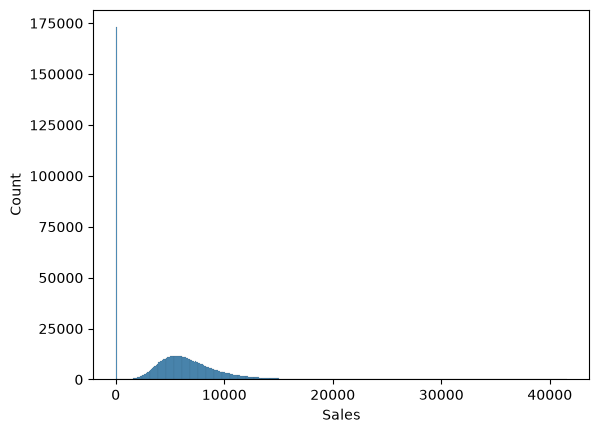

In [21]:
import plotly.express as px 
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.histplot(data=merged_df, x='Sales')

In [22]:
#Can you explain why the sales are 0 on so many dates?
merged_df.Open.value_counts()
#show how many day store closed or open

Open
1    844392
0    172817
Name: count, dtype: int64

In [23]:
merged_df.Sales.value_counts()[0]
#"Give me the count for where the index label equals 0"
#How many rows have Sales exactly equal to 0

np.int64(172871)

In [24]:
merged_df.Sales.value_counts()
#without [0] , you see all numer of sales counted

Sales
0        172871
5674        215
5558        197
5483        196
6049        195
          ...  
20050         1
1067          1
660           1
17815         1
23303         1
Name: count, Length: 21734, dtype: int64

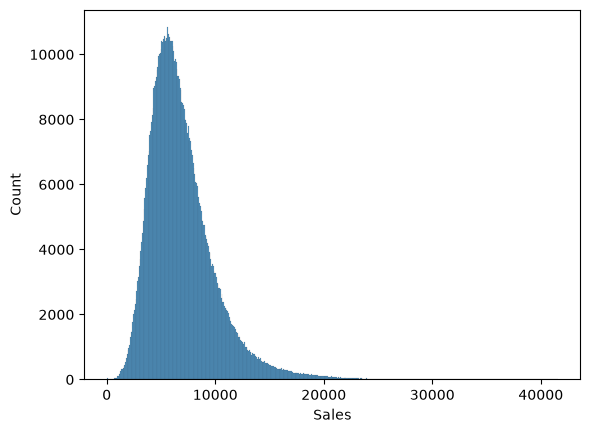

In [25]:
#How will your model predict zero sales on days when the store is closed? It is better to remove these rows from the dataset? will it affect the data for prediction? what should we do ? 
merged_df = merged_df[merged_df.Open==1].copy()
sns.histplot(data=merged_df, x='Sales');

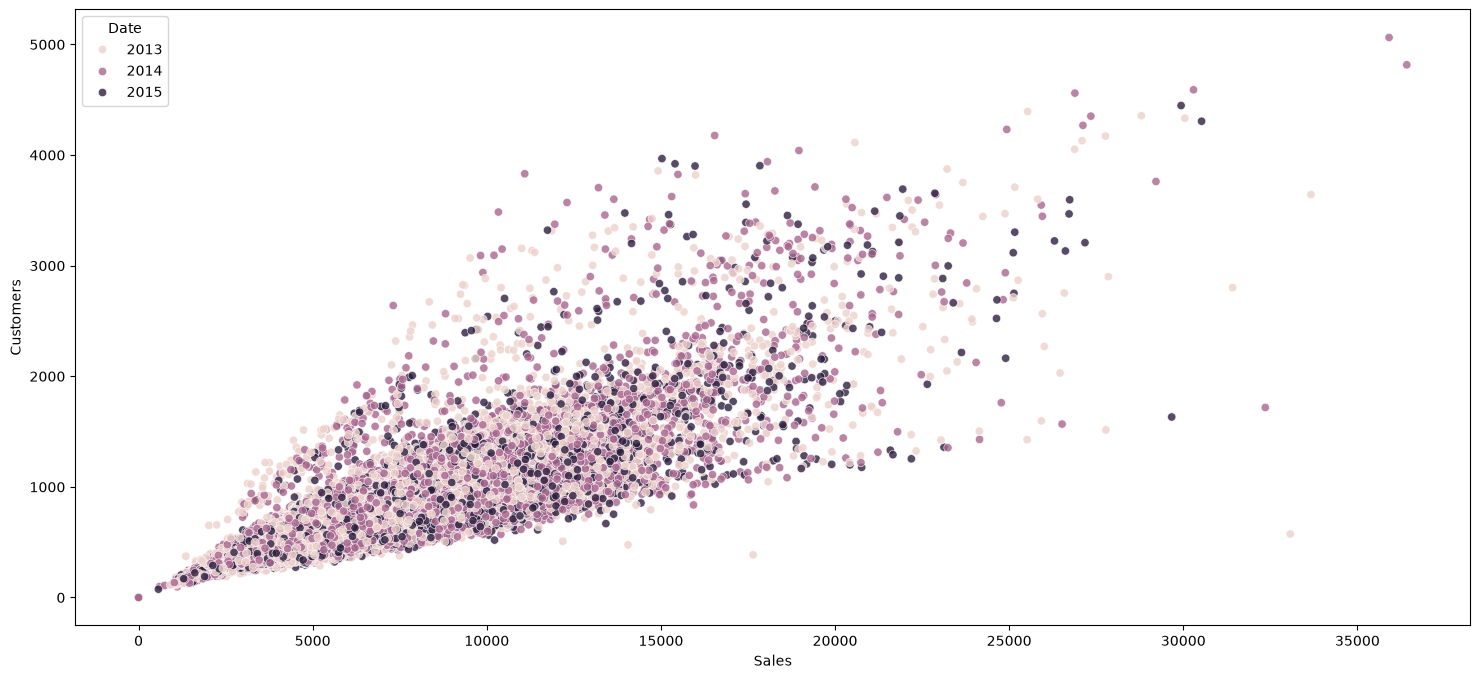

In [26]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(40000)
sns.scatterplot(x=temp_df.Sales, y =temp_df.Customers, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs Customers')
plt.show()
#X-axis (Sales) = how much money a store made in total, in one day (in currency, like dollars/euros)
#Y-axis (Customers) = how many individual people/transactions came into the store that same day

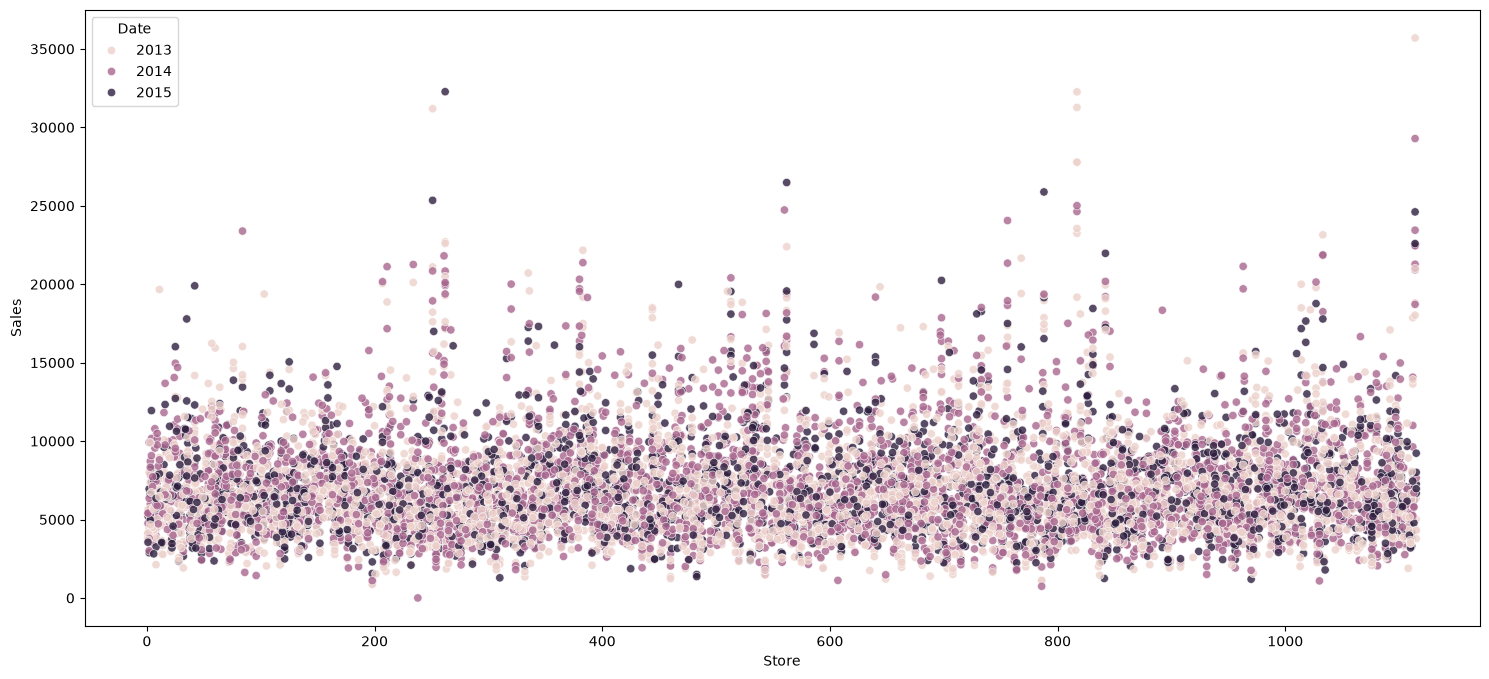

In [27]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(10000)
sns.scatterplot(x=temp_df.Store, y =temp_df.Sales, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs Store')
plt.show()
# there are 1115 different stores and each dot represent one of the stores sold in a day

<Axes: xlabel='DayOfWeek', ylabel='Sales'>

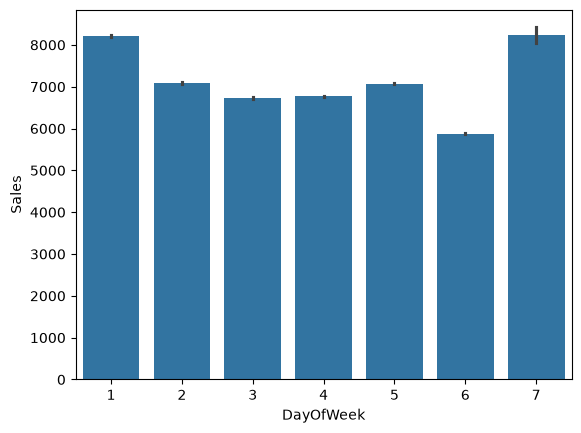

In [28]:
sns.barplot(data=merged_df, x='DayOfWeek', y='Sales')
#average Sales for each day of the week

<Axes: xlabel='Promo', ylabel='Sales'>

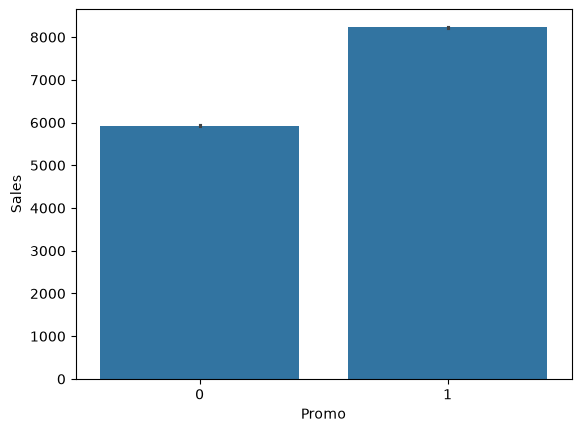

In [29]:
sns.barplot(data=merged_df, x='Promo', y='Sales')
#is a binary (0/1) column indicating whether a store was running a promotional sale/discount on that specific day


In [30]:
merged_df.corr(numeric_only=True)['Sales'].sort_values(ascending=False)

Sales                        1.000000
Customers                    0.823597
Promo                        0.368145
Promo2SinceWeek              0.095311
SchoolHoliday                0.038617
CompetitionOpenSinceYear     0.016101
Store                        0.007710
Promo2SinceYear             -0.034713
CompetitionDistance         -0.036396
CompetitionOpenSinceMonth   -0.043489
Promo2                      -0.127596
DayOfWeek                   -0.178736
Open                              NaN
Name: Sales, dtype: float64

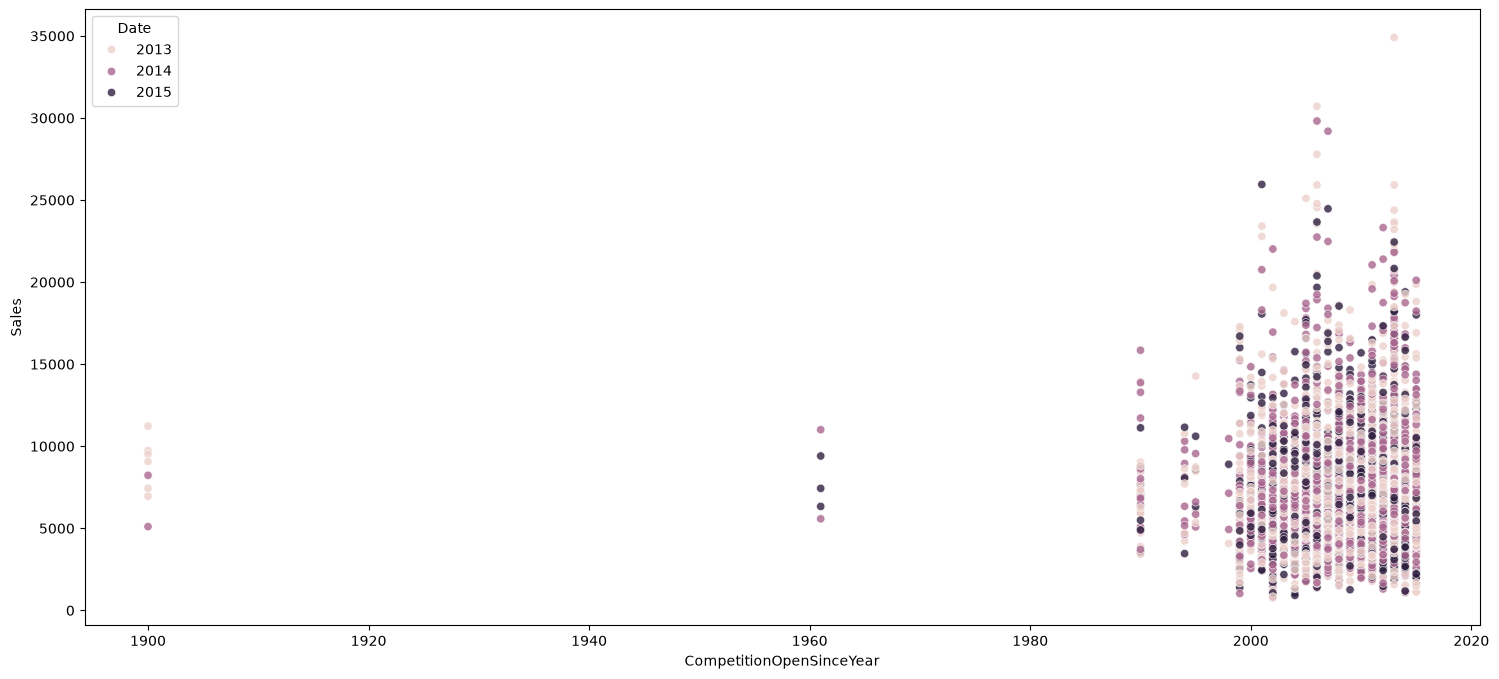

In [31]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(10000)
sns.scatterplot(x=temp_df.CompetitionOpenSinceYear, y =temp_df.Sales, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs CompetitionOpenSinceYear ')
plt.show()

In [32]:
#now we create a new feature from the existing one (Feature enginnering)
merged_df['Day'] = merged_df.Date.dt.day 
merged_df['Month'] = merged_df.Date.dt.month
merged_df['Year'] = merged_df.Date.dt.year

In [33]:
merged_test_df['Day'] = merged_test_df.Date.dt.day
merged_test_df['Month'] = merged_test_df.Date.dt.month
merged_test_df['Year'] = merged_test_df.Date.dt.year

<Axes: xlabel='Year', ylabel='Sales'>

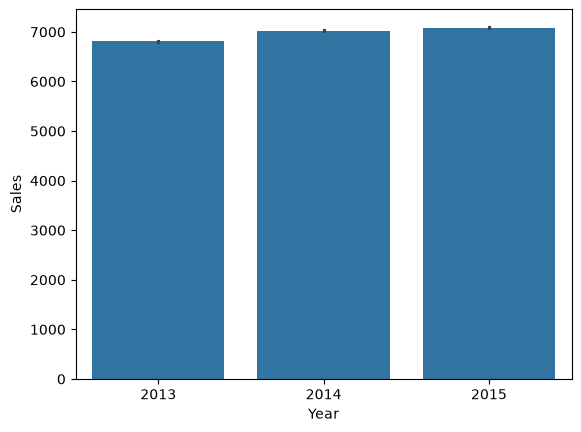

In [34]:
sns.barplot(merged_df, y= 'Sales', x = 'Year')

<Axes: xlabel='Month', ylabel='Sales'>

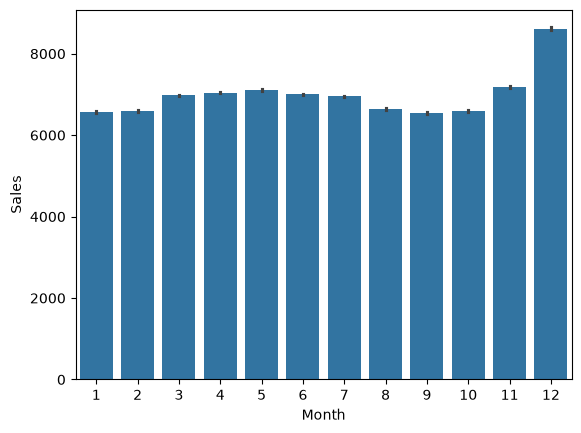

In [35]:
sns.barplot(data=merged_df, x='Month', y='Sales')

In [36]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,1270.0,9.0,2008.0,0,NaN,NaN,NaN,31,7,2015
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",31,7,2015
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",31,7,2015
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,620.0,9.0,2009.0,0,NaN,NaN,NaN,31,7,2015
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,29910.0,4.0,2015.0,0,NaN,NaN,NaN,31,7,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,150.0,9.0,2006.0,0,NaN,NaN,NaN,1,1,2013
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,860.0,10.0,1999.0,0,NaN,NaN,NaN,1,1,2013
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,840.0,NaN,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct",1,1,2013
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,1430.0,NaN,NaN,0,NaN,NaN,NaN,1,1,2013


In [37]:
%pip install holidays

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
import holidays
#Get all German public holidays for each year present in the dataset
# #use unique year in that
merged_df['Date']= pd.to_datetime(merged_df['Date'])
public_holiday = holidays.Germany(years=merged_df['Year'].unique())
#now time to create a new column with public holiday or not
merged_df['is_Public_holiday'] = merged_df['Date'].dt.date.isin(public_holiday)
#dt.date converts a Timestamp (datetime) into a Python datetime.date
merged_test_df['Date']= pd.to_datetime(merged_test_df['Date'])
merged_test_df['is_Public_holiday'] = merged_test_df['Date'].dt.date.isin(holidays.Germany(years=merged_test_df['Year'].unique()))


In [39]:
merged_test_df['is_Public_holiday'].value_counts()

is_Public_holiday
False    41088
Name: count, dtype: int64

In [40]:
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,is_Public_holiday
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,...,9.0,2008.0,0,NaN,NaN,NaN,17,9,2015,False
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",17,9,2015,False
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,...,4.0,2013.0,0,NaN,NaN,NaN,17,9,2015,False
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,...,10.0,2014.0,0,NaN,NaN,NaN,17,9,2015,False
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,...,8.0,2000.0,0,NaN,NaN,NaN,17,9,2015,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,...,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct",1,8,2015,False
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,...,4.0,2006.0,0,NaN,NaN,NaN,1,8,2015,False
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,...,NaN,NaN,0,NaN,NaN,NaN,1,8,2015,False
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,...,NaN,NaN,0,NaN,NaN,NaN,1,8,2015,False


In [41]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,is_Public_holiday
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,NaN,NaN,NaN,31,7,2015,False
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",31,7,2015,False
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",31,7,2015,False
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,NaN,NaN,NaN,31,7,2015,False
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,NaN,NaN,NaN,31,7,2015,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,9.0,2006.0,0,NaN,NaN,NaN,1,1,2013,True
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,10.0,1999.0,0,NaN,NaN,NaN,1,1,2013,True
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,NaN,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct",1,1,2013,True
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,NaN,NaN,0,NaN,NaN,NaN,1,1,2013,True


In [42]:
merged_df['is_Public_holiday'].value_counts()

is_Public_holiday
False    843793
True        599
Name: count, dtype: int64

In [43]:

# import requests
# url = "https://archive-api.open-meteo.com/v1/archive" 
# params = {
#   "latitude" : 52.52,
#   "longitude" : 13.41,
#   "start_date" : merged_df['Date'].min().strftime('%Y-%m-%d'),
#   "end_date" : merged_df['Date'].max().strftime('%Y-%m-%d'),
#   "daily" : "temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,snowfall_sum",
#   "timezone":"Europe/Berlin"
# }

In [44]:
# response = requests.get(url, params = params)
# weather_data = response.json()
# weather_df = pd.DataFrame(weather_data['daily'])
# weather_df['time'] = pd.to_datetime(weather_df['time'])
# weather_df.rename(columns={'time': 'Date'}, inplace=True)
# print(weather_df.head())

# -> now we don't do the weather since we don't have specific location

In [45]:
# weather_df.value_counts()

In [46]:
merged_df.value_counts()

Store  DayOfWeek  Date        Sales  Customers  Open  Promo  StateHoliday  SchoolHoliday  StoreType  Assortment  CompetitionDistance  CompetitionOpenSinceMonth  CompetitionOpenSinceYear  Promo2  Promo2SinceWeek  Promo2SinceYear  PromoInterval    Day  Month  Year  is_Public_holiday
2      5          2015-07-31  6064   625        1     1      0             1              a          a           570.0                11.0                       2007.0                    1       13.0             2010.0           Jan,Apr,Jul,Oct  31   7      2015  False                1
3      5          2015-07-31  8314   821        1     1      0             1              a          a           14130.0              12.0                       2006.0                    1       14.0             2011.0           Jan,Apr,Jul,Oct  31   7      2015  False                1
11     5          2015-07-31  10457  1236       1     1      0             1              a          c           960.0                11.0      

In [47]:
#merged_df['is_Rain'] = (merged_df['precipitation_sum'] > 0).astype(int)

In [48]:
# print(merged_df.columns.tolist())
# print([c for c in merged_df.columns if 'precip' in c.lower()])

In [49]:
# merged_df = merged_df.merge(weather_df, how = 'left', on= 'Date' )

In [50]:
merged_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday'],
      dtype='str')

In [51]:
store_df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [52]:
#Store=2, StoreType=a, Assortment=a, CompetitionDistance=570.0,
#CompetitionOpenSinceMonth=11.0, CompetitionOpenSinceYear=2007.0,
#Promo2=1, Promo2SinceWeek=13.0, Promo2SinceYear=2010.0, PromoInterval=Jan,Apr,Jul,Oct

#Plain English: Store #2 IS in the Promo2 program (Promo2=1). It joined starting week 13 of 2010 (roughly late March 2010), and its recurring promotion runs every January, April, July, and October each year since then.

In [53]:
#Store=1113, StoreType=a, Assortment=c, CompetitionDistance=9260.0,
#CompetitionOpenSinceMonth=NaN, CompetitionOpenSinceYear=NaN,
#Promo2=0, ...
#Plain English: Here, even CompetitionOpenSinceMonth/Year are blank — this likely means the exact date the nearest competitor opened is simply unknown/unrecorded, even though we know a competitor exists 9,260m away. This is genuinely missing data (not logically implied blank like the Promo2 case above).

In [54]:
#EXERCISE: The features Promo2, Promo2SinceWeek etc. are not very useful in their current form, because they do not relate to the current date. How can you improve their representation?
#Summary to find if promo2 still active until that specific date 
#Solution: 
#1. check if promo2 is available or not
#2. check if promoInterval is corrected or not(if that day(Date column) are not in range of PromoInterval , it means no promo2 actived on that date)
#3. check if Promo2SinceYear is corrected or not (if it is null or it is later that that day(date column) , it means false)
#4. same as #3 but check more if Promo2SinceYear and Date Column are in the same date but weeks-th of Date Column is smaller than PromoSinceYear's , there is no way it could happen, so false
#If they can cross all those, it mean is_activePromo is 1 


#we map from 1 : 3chars
month_map = {
   1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
#add one more column in dataset. that column is 3 chars Month
merged_df['MonthStr'] = merged_df['Date'].dt.month.map(month_map)
merged_test_df['MonthStr'] = merged_test_df['Date'].dt.month.map(month_map)

def is_promo2_active(row) : 
  if(row['Promo2']) ==0: 
    return 0
  if pd.isna(row['PromoInterval']):
    return 0
  active_months = row['PromoInterval'].split(',')
  if row['MonthStr'] not in active_months:
    return 0
  row_year, row_week, _ = row['Date'].isocalendar()
  if pd.isna(row['Promo2SinceYear']):
    return 0
  if row_year < row['Promo2SinceYear']:
    return 0
  if row_year == row['Promo2SinceYear'] and row_week <row['Promo2SinceWeek']:
    return 0
  
  return 1
# Apply the is_promo2_active() function to EVERY row in merged_df (axis=1 means "row-wise"),
# and store the resulting 0/1 values in a new column called 'IsPromo2Active'
merged_df['IsPromo2Active'] = merged_df.apply(is_promo2_active,axis = 1)
merged_test_df['IsPromo2Active'] = merged_test_df.apply(is_promo2_active,axis = 1)


In [55]:
store_df.to_csv('store.csv', index=False)  # only this would actually damage the file on disk

In [56]:
import numpy as np
def competition_open_months(row):
  if pd.isna(row['CompetitionOpenSinceYear']) or pd.isna(row['CompetitionOpenSinceMonth']):
    return np.nan
  months  = (row['Year'] - row['CompetitionOpenSinceYear']) * 12 + ((row['Month'] - row['CompetitionOpenSinceMonth']))
  return max(months, 0)

merged_df['Num_Month_CompetitionOpen'] = merged_df.apply(competition_open_months,axis= 1)
merged_test_df['Num_Month_CompetitionOpen'] = merged_test_df.apply(competition_open_months,axis= 1)

In [57]:
merged_df['HasCompetition'] = merged_df['Num_Month_CompetitionOpen'].notna().astype(int)
merged_test_df['HasCompetition'] = merged_test_df['Num_Month_CompetitionOpen'].notna().astype(int)


In [58]:
#make it very far
merged_df['Up_CompetitionDistance'] = merged_df['CompetitionDistance'].fillna(merged_df['CompetitionDistance'].max() * 3)
merged_test_df['Up_CompetitionDistance'] = merged_test_df['CompetitionDistance'].fillna(merged_df['CompetitionDistance'].max() * 3)
#just to make it very far aways

In [59]:
merged_df['CompetitionDistanceBucket'] = pd.cut(
  merged_df['Up_CompetitionDistance'],
  bins = [0, 1000, 5000, 20000, np.inf],
  labels = ['very_close', 'close', 'moderate', 'far']
)
merged_test_df['CompetitionDistanceBucket'] = pd.cut(
  merged_test_df['Up_CompetitionDistance'],
  bins = [0, 1000, 5000, 20000, np.inf],
  labels = ['very_close', 'close', 'moderate', 'far']
)

In [60]:
# good for linear regression or a neural network
merged_df['CompetitionDistance_log'] = np.log1p(merged_df['CompetitionDistance'])
# good for linear regression or a neural network
merged_test_df['CompetitionDistance_log'] = np.log1p(merged_test_df['CompetitionDistance'])

In [61]:
merged_df[['CompetitionOpenSinceYear', 'Num_Month_CompetitionOpen', 'HasCompetition', 'CompetitionDistance', 'Up_CompetitionDistance', 'CompetitionDistanceBucket', 'CompetitionDistance_log']]

,CompetitionOpenSinceYear,Num_Month_CompetitionOpen,HasCompetition,CompetitionDistance,Up_CompetitionDistance,CompetitionDistanceBucket,CompetitionDistance_log
0,2008.0,82.0,1,1270.0,1270.0,close,7.147559
1,2007.0,92.0,1,570.0,570.0,very_close,6.347389
2,2006.0,103.0,1,14130.0,14130.0,moderate,9.556126
3,2009.0,70.0,1,620.0,620.0,very_close,6.431331
4,2015.0,3.0,1,29910.0,29910.0,far,10.305982
...,...,...,...,...,...,...,...
1016776,2006.0,76.0,1,150.0,150.0,very_close,5.017280
1016827,1999.0,159.0,1,860.0,860.0,very_close,6.758095
1016863,NaN,NaN,0,840.0,840.0,very_close,6.734592
1017042,NaN,NaN,0,1430.0,1430.0,close,7.266129


In [ ]:
# test_cutoff = the max(2015-07-31 00:00:00) minus 6 weeks , meaning the result around(2015-06-16 00:00:00)
#test_cutoff = merged_df['Date'].max() - pd.Timedelta(weeks = 6)
# test_df is only date that is bigger than 2015-06-16 00:00:00 
#test_df = merged_df[merged_df['Date'] > test_cutoff]
#train and val _df is only date that is smaller than 2015-06-16 00:00:00 
sort_df = merged_df.sort_values('Date')
train_size = int(.75 * len(sort_df))
train_df, val_df = sort_df[:train_size] , sort_df[train_size:]


In [63]:
print(test_df.shape)
print(train_df.shape)
print(val_df.shape)

(41088, 8)
(633294, 29)
(211098, 29)


In [64]:
train_df.Date.min(), train_df.Date.max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2014-12-10 00:00:00'))

In [65]:
val_df.Date.min(), val_df.Date.max()

(Timestamp('2014-12-10 00:00:00'), Timestamp('2015-07-31 00:00:00'))

In [66]:
merged_test_df.Date.min(), merged_test_df.Date.max()

(Timestamp('2015-08-01 00:00:00'), Timestamp('2015-09-17 00:00:00'))

In [67]:
train_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket', 'CompetitionDistance_log'],
      dtype='str')

In [68]:
# Option A: fill with 0 (as a flag/placeholder, since no competitor = no open date)
merged_df['CompetitionOpenSinceMonth'] = merged_df['CompetitionOpenSinceMonth'].fillna(0)
merged_df['CompetitionOpenSinceYear'] = merged_df['CompetitionOpenSinceYear'].fillna(0)

In [69]:
#we don't have specific customer in reality
input_cols = merged_df.drop(columns=['Sales', 'Customers']).columns.tolist()
target_col = ['Sales', 'Customers']

In [70]:
train_inputs = train_df[input_cols].copy()
train_target = train_df[target_col].copy()

In [71]:
val_inputs = val_df[input_cols].copy()
val_targets = val_df[target_col].copy()

In [72]:
test_inputs = merged_test_df[input_cols].copy()
# Test data does not have targets

In [73]:
train_inputs

,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket,CompetitionDistance_log
1017190,1097,2,2013-01-01,1,0,a,1,b,b,720.0,...,1,2013,True,Jan,0,130.0,1,720.0,very_close,6.580639
1016179,85,2,2013-01-01,1,0,a,1,b,a,1870.0,...,1,2013,True,Jan,0,15.0,1,1870.0,close,7.534228
1016353,259,2,2013-01-01,1,0,a,1,b,b,210.0,...,1,2013,True,Jan,0,NaN,0,210.0,very_close,5.351858
1016356,262,2,2013-01-01,1,0,a,1,b,a,1180.0,...,1,2013,True,Jan,0,0.0,1,1180.0,close,7.074117
1016368,274,2,2013-01-01,1,0,a,1,b,b,3640.0,...,1,2013,True,Jan,0,NaN,0,3640.0,close,8.200014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256632,745,3,2014-12-10,1,0,0,0,a,a,17650.0,...,12,2014,False,Dec,0,13.0,1,17650.0,moderate,9.778548
256642,756,3,2014-12-10,1,0,0,0,a,c,50.0,...,12,2014,False,Dec,0,NaN,0,50.0,very_close,3.931826
256634,747,3,2014-12-10,1,0,0,0,c,c,45740.0,...,12,2014,False,Dec,0,76.0,1,45740.0,far,10.730750
256633,746,3,2014-12-10,1,0,0,0,d,c,4330.0,...,12,2014,False,Dec,1,46.0,1,4330.0,close,8.373554


In [74]:
train_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket', 'CompetitionDistance_log'],
      dtype='str')

In [75]:
train_inputs.columns

Index(['Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday',
       'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance',
       'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2',
       'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Day', 'Month',
       'Year', 'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket', 'CompetitionDistance_log'],
      dtype='str')

In [76]:
train_inputs

,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket,CompetitionDistance_log
1017190,1097,2,2013-01-01,1,0,a,1,b,b,720.0,...,1,2013,True,Jan,0,130.0,1,720.0,very_close,6.580639
1016179,85,2,2013-01-01,1,0,a,1,b,a,1870.0,...,1,2013,True,Jan,0,15.0,1,1870.0,close,7.534228
1016353,259,2,2013-01-01,1,0,a,1,b,b,210.0,...,1,2013,True,Jan,0,NaN,0,210.0,very_close,5.351858
1016356,262,2,2013-01-01,1,0,a,1,b,a,1180.0,...,1,2013,True,Jan,0,0.0,1,1180.0,close,7.074117
1016368,274,2,2013-01-01,1,0,a,1,b,b,3640.0,...,1,2013,True,Jan,0,NaN,0,3640.0,close,8.200014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256632,745,3,2014-12-10,1,0,0,0,a,a,17650.0,...,12,2014,False,Dec,0,13.0,1,17650.0,moderate,9.778548
256642,756,3,2014-12-10,1,0,0,0,a,c,50.0,...,12,2014,False,Dec,0,NaN,0,50.0,very_close,3.931826
256634,747,3,2014-12-10,1,0,0,0,c,c,45740.0,...,12,2014,False,Dec,0,76.0,1,45740.0,far,10.730750
256633,746,3,2014-12-10,1,0,0,0,d,c,4330.0,...,12,2014,False,Dec,1,46.0,1,4330.0,close,8.373554


In [77]:
test_inputs

,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket,CompetitionDistance_log
0,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,...,9,2015,False,Sep,0,84.0,1,1270.0,close,7.147559
1,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,...,9,2015,False,Sep,0,105.0,1,14130.0,moderate,9.556126
2,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,...,9,2015,False,Sep,0,29.0,1,24000.0,far,10.085851
3,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,...,9,2015,False,Sep,0,11.0,1,7520.0,moderate,8.925454
4,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,...,9,2015,False,Sep,0,181.0,1,2030.0,close,7.616284
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,...,8,2015,False,Aug,0,14.0,1,1900.0,close,7.550135
41084,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,...,8,2015,False,Aug,0,112.0,1,1880.0,close,7.539559
41085,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,...,8,2015,False,Aug,0,NaN,0,9260.0,moderate,9.133567
41086,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,...,8,2015,False,Aug,0,NaN,0,870.0,very_close,6.769642


In [78]:
numeric_cols = train_inputs[input_cols].select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = train_inputs[input_cols].select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'IsPromo2Active', 'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance', 'CompetitionDistance_log']
Categorical columns: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'is_Public_holiday', 'MonthStr', 'CompetitionDistanceBucket']


C:\Users\User\AppData\Local\Temp\ipykernel_31732\1674847508.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = train_inputs[input_cols].select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


In [79]:
# now , just choose specific column i think ... let rest


In [80]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket,CompetitionDistance_log
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,7,2015,False,Jul,0,82.0,1,1270.0,close,7.147559
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,7,2015,False,Jul,1,92.0,1,570.0,very_close,6.347389
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,7,2015,False,Jul,1,103.0,1,14130.0,moderate,9.556126
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,7,2015,False,Jul,0,70.0,1,620.0,very_close,6.431331
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,7,2015,False,Jul,0,3.0,1,29910.0,far,10.305982
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,1,2013,True,Jan,0,76.0,1,150.0,very_close,5.017280
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,1,2013,True,Jan,0,159.0,1,860.0,very_close,6.758095
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,1,2013,True,Jan,1,NaN,0,840.0,very_close,6.734592
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,1,2013,True,Jan,0,NaN,0,1430.0,close,7.266129


In [81]:
merged_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket', 'CompetitionDistance_log'],
      dtype='str')

In [82]:
merged_df["Date"] = pd.to_datetime(merged_df["Date"])
# here is where we need to input the store number and get the specific store data in the website. 
def store_id(store_num):
  each_store_id = (merged_df[merged_df["Store"] == store_num]
          .sort_values("Date")
          .reset_index(drop=True))
  return each_store_id

store_id(store_num=1)
#without weekend(with sunday,model weak)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket,CompetitionDistance_log
0,1,3,2013-01-02,5530,668,1,0,0,1,c,...,1,2013,False,Jan,0,52.0,1,1270.0,close,7.147559
1,1,4,2013-01-03,4327,578,1,0,0,1,c,...,1,2013,False,Jan,0,52.0,1,1270.0,close,7.147559
2,1,5,2013-01-04,4486,619,1,0,0,1,c,...,1,2013,False,Jan,0,52.0,1,1270.0,close,7.147559
3,1,6,2013-01-05,4997,635,1,0,0,1,c,...,1,2013,False,Jan,0,52.0,1,1270.0,close,7.147559
4,1,1,2013-01-07,7176,785,1,1,0,1,c,...,1,2013,False,Jan,0,52.0,1,1270.0,close,7.147559
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
776,1,1,2015-07-27,6102,612,1,1,0,1,c,...,7,2015,False,Jul,0,82.0,1,1270.0,close,7.147559
777,1,2,2015-07-28,5011,560,1,1,0,1,c,...,7,2015,False,Jul,0,82.0,1,1270.0,close,7.147559
778,1,3,2015-07-29,4782,523,1,1,0,1,c,...,7,2015,False,Jul,0,82.0,1,1270.0,close,7.147559
779,1,4,2015-07-30,5020,546,1,1,0,1,c,...,7,2015,False,Jul,0,82.0,1,1270.0,close,7.147559


In [83]:
dates = set(store_id(store_num=1)["Date"])
full = pd.date_range(store_id(store_num=1)["Date"].min(), store_id(store_num=1)["Date"].max())
missing = [d for d in full if d.dayofweek != 7 and d not in dates]   # Sunday = 6
print(len(missing), missing[:10])

160 [Timestamp('2013-01-06 00:00:00'), Timestamp('2013-01-13 00:00:00'), Timestamp('2013-01-20 00:00:00'), Timestamp('2013-01-27 00:00:00'), Timestamp('2013-02-03 00:00:00'), Timestamp('2013-02-10 00:00:00'), Timestamp('2013-02-17 00:00:00'), Timestamp('2013-02-24 00:00:00'), Timestamp('2013-03-03 00:00:00'), Timestamp('2013-03-10 00:00:00')]


In [84]:
import pandas as pd
print(pd.crosstab(merged_df['DayOfWeek'], merged_df['Open']))


Open            1
DayOfWeek        
1          137560
2          143961
3          141936
4          134644
5          138640
6          144058
7            3593
